In [ ]:
#import balickov a dat
import pandas as pd
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt

arr = np.array([
    [460, 380, 550, 300, 420, 260, 580, 400, 500, 320, 430, 280],
    [45, 37, 58, 30, 42, 25, 62, 40, 52, 31, 43, 27],
    [18500, 15800, 22300, 13200, 17200, 11000, 24000, 16800, 20500, 13800, 18200, 11500],
    [220000, 185000, 260000, 150000, 205000, 125000, 280000, 195000, 245000, 155000, 210000, 135000]
], dtype=float)
indexy = ["N" + str(i) for i in range(1, 13)]

df = pd.DataFrame(arr.T).set_axis(["Personál", "Náklady (mil. eur)", "Hospitalizácie", "Ambulatné výkony"], axis=1)
df = df.set_axis(indexy, axis=0)
df.index.name = "Nemocnica"

X = df.loc[:, ["Personál", "Náklady (mil. eur)"]].to_numpy()
Y = df.loc[:, ["Hospitalizácie", "Ambulatné výkony"]].to_numpy()

n = X.shape[0]
ones_i = np.ones(X.shape[1])
ones_o = np.ones(Y.shape[1])

In [ ]:
#funkcia, ktora pocita BCC-O-OM a CCR-O-OM
def bccccr(X, Y, model):
  if model != "BCC" and model != "CCR":
    print("invalid model")

    return

  efektivity = []
  for o in range(1, 13):

    phi = cp.Variable(nonneg=True)
    lam = cp.Variable(n, nonneg=True)

    objective = cp.Maximize(phi)
    constraints = [X.T @ lam <= X[o - 1],
                  Y.T @ lam >= phi * Y[o - 1],
                  ]

    if model == "BCC":
      constraints.append(cp.sum(lam) == 1)

    problem = cp.Problem(objective, constraints)
    problem.solve()
    efektivity.append(np.clip(1 / phi.value, a_min = 0, a_max=1))

  return np.array(efektivity)

In [ ]:
#druha faza na indentifikaciu pseudoefektivity
def faza(X, Y, efektivity):
  ucel = []
  s_o = []
  s_i = []
  lambdy = []

  for o in range(1, 13):

    phi = cp.Variable(nonneg=True)
    lam = cp.Variable(n, nonneg=True)

    slack_i = cp.Variable(X.shape[1], nonneg=True)
    slack_o = cp.Variable(Y.shape[1], nonneg=True)

    objective = cp.Maximize(slack_i @ ones_i + slack_o @ ones_o)
    constraints = [X.T @ lam + slack_i == X[o - 1],
                  Y.T @ lam - slack_o == (1 / efektivity[o-1]) * Y[o - 1],
                  cp.sum(lam) == 1
                  ]
    problem = cp.Problem(objective, constraints)
    problem.solve()
    if objective.value <= 1e-7:
      ucel.append(0)
    else:
      ucel.append(objective.value)

    s_o.append(slack_o.value)
    s_i.append(slack_i.value)

    lambd = lam.value
    for i in range(len(lambd)):
      if lambd[i] <= 1e-7:
        lambd[i] = 0

    lambdy.append(lambd)

  ucel = np.array(ucel)
  s_o = np.array(s_o)
  s_o[s_o <= 1e-7] = 0
  s_i = np.array(s_i)
  s_i[s_i <= 1e-7] = 0

  return ucel, s_o, s_i, np.array(lambdy)

In [ ]:
#vysledky
bcc = bccccr(X, Y, model="BCC")
ccr = bccccr(X, Y, model="CCR")
print("----------BCC vysledky----------")
print(bcc, "\n")
print("----------CCR vysledky----------")
print(ccr, "\n")

scale_eff = np.array(ccr)/np.array(bcc)
print("------Rozsahova efektivita DMUs-------")
print(scale_eff, "\n")

ucel, s_o, s_i, lambdy = faza(X, Y, bcc)
print("---------Hodnota Ucel funkcie---------")
print(ucel, "\n")
print("---------Slacky_output---------")
print(s_o, "\n")
print("---------Slacky_input---------")
print(s_i, "\n")
print("---------Lambdy---------")
print(lambdy)

----------BCC vysledky----------
[1.         1.         0.97965976 1.         0.99812734 1.
 1.         0.99411765 1.         1.         1.         1.        ] 

----------CCR vysledky----------
[0.97777778 1.         0.94545455 1.         0.97619048 1.
 0.96551725 0.975      0.98       1.         0.97674419 1.        ] 

------Rozsahova efektivita DMUs-------
[0.97777778 1.         0.9650846  1.         0.97802198 1.
 0.96551725 0.98076923 0.98       1.         0.97674419 1.        ] 

---------Hodnota Ucel funkcie---------
[  0.           0.           0.8501553    0.         583.11503601
   0.           0.         146.74601979   0.           0.
   0.         433.33333546] 

---------Slacky_output---------
[[0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 7.79946436e-04]
 [0.00000000e+00 0.00000000e+00]
 [5.83114484e+02 5.51632838e-04]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [1.46745598e+02 4.21486678e-04]
 [0.00000000e+00 0.

In [ ]:
lambdy = np.round(lambdy, decimals=7)
Y_hat = lambdy @ Y

array = np.array([
    X[:, 0],
    X[:, 1],
    Y_hat[:, 0],
    Y_hat[:, 1],
], dtype=float)
array
indexy = ["N" + str(i) for i in range(1, 13)]

dataframe = pd.DataFrame(array.T).set_axis(["Personál", "Náklady (mil. eur)", "Hospitalizácie", "Ambulatné výkony"], axis=1)
dataframe = dataframe.set_axis(indexy, axis=0)
dataframe.index.name = "Nemocnica"

print(df, "\n")
print(dataframe, "\n")
print(dataframe - df)

           Personál  Náklady (mil. eur)  Hospitalizácie  Ambulatné výkony
Nemocnica                                                                
N1            460.0                45.0         18500.0          220000.0
N2            380.0                37.0         15800.0          185000.0
N3            550.0                58.0         22300.0          260000.0
N4            300.0                30.0         13200.0          150000.0
N5            420.0                42.0         17200.0          205000.0
N6            260.0                25.0         11000.0          125000.0
N7            580.0                62.0         24000.0          280000.0
N8            400.0                40.0         16800.0          195000.0
N9            500.0                52.0         20500.0          245000.0
N10           320.0                31.0         13800.0          155000.0
N11           430.0                43.0         18200.0          210000.0
N12           280.0                27.

In [ ]:
lambdy = np.round(lambdy, decimals=7)
Y_cat = Y * (1/bcc)[:, None]

array = np.array([
    X[:, 0],
    X[:, 1],
    Y_cat[:, 0],
    Y_cat[:, 1],
], dtype=float)
array
indexy = ["N" + str(i) for i in range(1, 13)]

dataframe = pd.DataFrame(array.T).set_axis(["Personál", "Náklady (mil. eur)", "Hospitalizácie", "Ambulatné výkony"], axis=1)
dataframe = dataframe.set_axis(indexy, axis=0)
dataframe.index.name = "Nemocnica"

print(df, "\n")
print(dataframe, "\n")
print(dataframe - df)
print(s_o)
print(s_i)

           Personál  Náklady (mil. eur)  Hospitalizácie  Ambulatné výkony
Nemocnica                                                                
N1            460.0                45.0         18500.0          220000.0
N2            380.0                37.0         15800.0          185000.0
N3            550.0                58.0         22300.0          260000.0
N4            300.0                30.0         13200.0          150000.0
N5            420.0                42.0         17200.0          205000.0
N6            260.0                25.0         11000.0          125000.0
N7            580.0                62.0         24000.0          280000.0
N8            400.0                40.0         16800.0          195000.0
N9            500.0                52.0         20500.0          245000.0
N10           320.0                31.0         13800.0          155000.0
N11           430.0                43.0         18200.0          210000.0
N12           280.0                27.

#Kreslenie

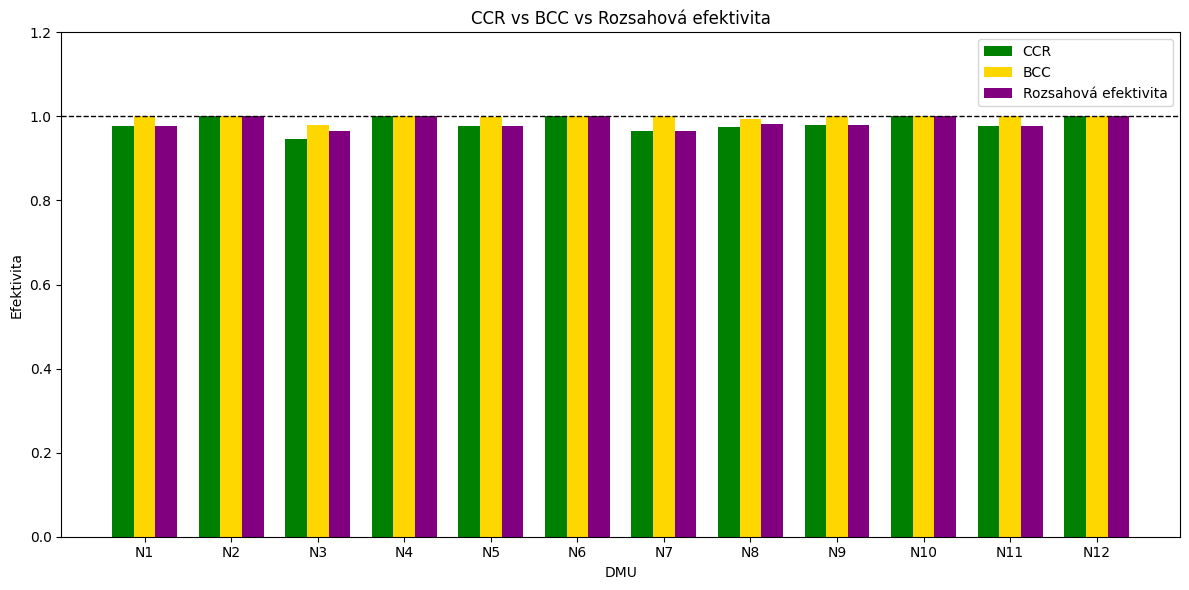

In [ ]:
dmu = [f"N{i}" for i in range(1, 13)]

x = np.arange(len(dmu))
width = 0.25

plt.figure(figsize=(12,6))

plt.bar(x - width, ccr, width, label="CCR", color="green")
plt.bar(x, bcc, width, label="BCC", color="gold")
plt.bar(x + width, scale_eff, width, label="Rozsahová efektivita", color="purple")

plt.axhline(y=1, color='black', linestyle='--', linewidth=1)

plt.xticks(x, dmu)
plt.ylim(0, 1.2)

plt.ylabel("Efektivita")
plt.xlabel("DMU")
plt.title("CCR vs BCC vs Rozsahová efektivita")
plt.legend()

plt.tight_layout()
plt.savefig("efektivita.pdf")
plt.show()

In [ ]:
print((np.argsort(scale_eff) + 1)[::-1])
print()
print(np.arange(1, 13))
print()
print(scale_eff)
print()
print(bcc)
print()
print(ccr)



[12 10  4  6  2  8  9  5  1 11  7  3]

[ 1  2  3  4  5  6  7  8  9 10 11 12]

[0.97777778 1.         0.9650846  1.         0.97802198 1.
 0.96551725 0.98076923 0.98       1.         0.97674419 1.        ]

[1.         1.         0.97965976 1.         0.99812734 1.
 1.         0.99411765 1.         1.         1.         1.        ]

[0.97777778 1.         0.94545455 1.         0.97619048 1.
 0.96551725 0.975      0.98       1.         0.97674419 1.        ]
